# Lab03 – Bài 1: Tìm kiếm cục bộ trên mê cung (Hill Climbing)

**Người thực hiện:** Nguyễn Hữu Tri — MSSV: 3123410387  
**Dữ liệu:** `L_maze.txt` và `maze_helper.py` (trong thư mục Lab03)

**Mục tiêu:** (1) Phân tích `expand()`, khoảng cách Manhattan và cách `local_search()` chọn láng giềng; (2) chạy Hill Climbing và quan sát animation; (3) ghi nhận vị trí dừng so với đích `G`; (4) thay đổi thứ tự hướng và ngẫu nhiên hóa để đánh giá hiện tượng mắc kẹt.

Notebook giữ cấu trúc ví dụ ban đầu, bổ sung thống kê, kiểm tra và hình minh họa. **Bài 1 chỉ nghiên cứu Hill Climbing trên mê cung**, không thay thế bằng BFS/A*; BFS chỉ được dùng ở cuối để xác minh mê cung thực sự có đường đi đến đích.

## 1. Chuẩn bị dữ liệu và hiển thị mê cung

In [1]:
from pathlib import Path
import sys

# Chạy được khi mở VS Code/Jupyter ngay trong thư mục Lab03 hoặc từ gốc repository.
lab_dir = Path.cwd()
if not (lab_dir / 'L_maze.txt').is_file():
    lab_dir = lab_dir / 'weekly assignments' / 'lab03 - local search'
if not (lab_dir / 'L_maze.txt').is_file() or not (lab_dir / 'maze_helper.py').is_file():
    raise FileNotFoundError('Cần đặt L_maze.txt và maze_helper.py cùng thư mục notebook.')
if str(lab_dir) not in sys.path:
    sys.path.insert(0, str(lab_dir))
print('Đã tìm thấy dữ liệu trong thư mục:', lab_dir.name)

Đã tìm thấy dữ liệu trong thư mục: lab03 - local search


Kích thước: (15, 15); S = (9, 5); G = (2, 12)


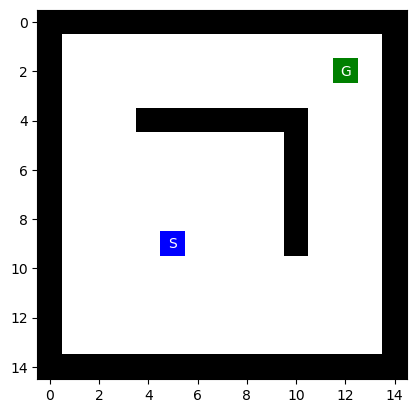

In [2]:
import numpy as np
import maze_helper as mh

with (lab_dir / 'L_maze.txt').open(encoding='utf-8') as f:
    maze = mh.parse_maze(f.read())

start_pos = tuple(map(int, mh.find_pos(maze, 'S')))
goal_pos = tuple(map(int, mh.find_pos(maze, 'G')))
print(f'Kích thước: {maze.shape}; S = {start_pos}; G = {goal_pos}')
mh.show_maze(maze)

## 2. Trạng thái lân cận và hàm mục tiêu

- **Trạng thái:** tọa độ ô `(r, c)` đang đứng.
- **Láng giềng:** các ô kề theo bốn hướng **N, E, S, W**, trừ ô tường (`X`). Hàm `expand()` sinh láng giềng hợp lệ.
- **Thứ tự xét hướng:** `set_order(order, random)`; thứ tự chỉ có thể đổi lựa chọn khi nhiều láng giềng **cùng đạt giá trị tốt nhất**. Khi `random=True`, danh sách được xáo trộn tại mỗi lần mở rộng.
- **Mục tiêu:** cực tiểu hóa khoảng cách Manhattan từ ô hiện tại đến `G`.

In [3]:
DIR2POS = {
    'N': (-1, 0),
    'E': ( 0, 1),
    'S': ( 1, 0),
    'W': ( 0,-1),
}
ORDER = None
RANDOMIZATION = None
DIRS = None

def set_order(order='NESW', random=False, verbose=True):
    """Đặt thứ tự duyệt; chọn thứ tự sẽ quyết định tie-break khi h bằng nhau."""
    global RANDOMIZATION, ORDER, DIRS
    if len(order) != 4 or set(order) != set(DIR2POS):
        raise ValueError('order phải gồm N, E, S, W đúng một lần')
    RANDOMIZATION = bool(random)
    ORDER = list(order)
    DIRS = [DIR2POS[direction] for direction in ORDER]
    if verbose:
        print('Duyệt ngẫu nhiên ở mỗi bước.' if RANDOMIZATION else f'Thứ tự hướng: {"".join(ORDER)}')

set_order('NESW')

Thứ tự hướng: NESW


In [4]:
def expand(maze, pos):
    """Trả về các cặp [hướng, vị trí] không đi vào tường."""
    available = [
        [direction, new_pos]
        for direction, new_pos in zip(ORDER, np.add(pos, DIRS))
        if (0 <= new_pos[0] < maze.shape[0]
            and 0 <= new_pos[1] < maze.shape[1]
            and mh.look(maze, new_pos) != 'X')
    ]
    if RANDOMIZATION:
        np.random.shuffle(available)
    return available

print('Láng giềng hợp lệ tại S:', [(direction, tuple(map(int, p))) for direction, p in expand(maze, start_pos)])

Láng giềng hợp lệ tại S: [('N', (8, 5)), ('E', (9, 6)), ('S', (10, 5)), ('W', (9, 4))]


### Khoảng cách Manhattan

\[
h(r,c)=|r-r_G|+|c-c_G|.
\]

Một bước **cải thiện** khi `h(mới) < h(hiện tại)`. Do chỉ di chuyển một ô theo N/E/S/W, mỗi bước hợp lệ làm `h` tăng hoặc giảm đúng 1. Thuật toán Hill Climbing không tích lũy đường tìm kiếm hay chi phí thực tế như BFS/A*.

In [5]:
def manhattan(pos1, pos2):
    """Khoảng cách Manhattan giữa hai vị trí."""
    return int(np.sum(np.abs(np.subtract(pos1, pos2))))

assert manhattan((0, 0), (1, 1)) == 2
print('h(S) =', manhattan(start_pos, goal_pos))

h(S) = 14


In [6]:
def local_search(maze, vis=False, animation=False, verbose=False):
    """Giữ cách chọn *láng giềng tốt nhất* của notebook gốc; thêm thống kê.

    `solution` là trạng thái dừng, KHÔNG có nghĩa đã đến G.
    `path` chỉ được đánh dấu là nghiệm nếu thuật toán thật sự tới G.
    """
    del vis  # tham số tương thích với hàm mẫu
    start = tuple(map(int, mh.find_pos(maze, 'S')))
    goal = tuple(map(int, mh.find_pos(maze, 'G')))
    current = start
    current_obj = manhattan(current, goal)
    trace = [start]
    h_history = [current_obj]
    actions = []
    evaluations = 1  # tính h cho trạng thái S
    maze_anim = [maze.copy()] if animation else None
    stop_reason = 'no_improvement'

    while True:
        if current_obj == 0:
            stop_reason = 'goal'
            break
        moves = expand(maze, current)
        if not moves:
            stop_reason = 'no_neighbors'
            break
        obj = [manhattan(pos, goal) for _, pos in moves]
        evaluations += len(obj)
        best_index = int(np.argmin(obj))
        best_obj = obj[best_index]
        direction, best_pos = moves[best_index]

        if verbose:
            print(f'Hiện tại {tuple(current)}: h = {current_obj}')
            print('Láng giềng:', [(d, tuple(map(int, p))) for d, p in moves])
            print('Giá trị h:', obj)

        if best_obj >= current_obj:
            if verbose:
                print('Không có láng giềng cải thiện. Dừng.\n')
            break

        current = tuple(map(int, best_pos))
        current_obj = best_obj
        trace.append(current)
        h_history.append(current_obj)
        actions.append(direction)
        if verbose:
            print(f'Chọn {direction} -> {current}, h = {current_obj}\n')
        if animation:
            frame = maze.copy()
            for r, c in trace[1:]:
                if frame[r, c] == ' ':
                    frame[r, c] = 'P'
            maze_anim.append(frame)

    solved = (current == goal)
    return {
        'solution': current,
        'path': trace if solved else None,
        'reached': trace if solved else None,
        'actions': actions if solved else None,
        'maze_anim': maze_anim,
        'trace': trace,
        'h_history': h_history,
        'steps': len(actions),
        'evaluations': evaluations,
        'success': solved,
        'stop_reason': stop_reason,
    }

## 3. Chạy thuật toán gốc và quan sát animation

Thiết lập `ORDER=NESW`, không ngẫu nhiên. Theo quy tắc thực tế trong code, **mỗi bước đánh giá tất cả láng giềng hợp lệ rồi chọn `h` nhỏ nhất**; đây là kiểu *best-improvement/steepest-descent theo h*, không phải bản first-improvement thường gọi là Simple Hill Climbing. Giữ nguyên quy tắc này để bám đúng ví dụ của đề. Khi nhiều láng giềng cùng tốt nhất, thứ tự hướng quyết định cách phá hòa (*tie-break*).

In [7]:
from time import perf_counter
from IPython.display import display

set_order('NESW', random=False, verbose=False)
t0 = perf_counter()
result = local_search(maze, animation=True, verbose=True)
elapsed_ms = (perf_counter() - t0) * 1000
print('Vị trí dừng result["solution"]:', result['solution'])
print('Đích G:', goal_pos)
print(f'Đến đích: {result["success"]} | Số bước: {result["steps"]} | '
      f'Số lần đánh giá h: {result["evaluations"]} | Thời gian: {elapsed_ms:.3f} ms')
print('Lý do dừng:', result['stop_reason'])
display(mh.animate_maze(result))

Hiện tại (9, 5): h = 14
Láng giềng: [('N', (8, 5)), ('E', (9, 6)), ('S', (10, 5)), ('W', (9, 4))]
Giá trị h: [13, 13, 15, 15]
Chọn N -> (8, 5), h = 13

Hiện tại (8, 5): h = 13
Láng giềng: [('N', (7, 5)), ('E', (8, 6)), ('S', (9, 5)), ('W', (8, 4))]
Giá trị h: [12, 12, 14, 14]
Chọn N -> (7, 5), h = 12

Hiện tại (7, 5): h = 12
Láng giềng: [('N', (6, 5)), ('E', (7, 6)), ('S', (8, 5)), ('W', (7, 4))]
Giá trị h: [11, 11, 13, 13]
Chọn N -> (6, 5), h = 11

Hiện tại (6, 5): h = 11
Láng giềng: [('N', (5, 5)), ('E', (6, 6)), ('S', (7, 5)), ('W', (6, 4))]
Giá trị h: [10, 10, 12, 12]
Chọn N -> (5, 5), h = 10

Hiện tại (5, 5): h = 10
Láng giềng: [('E', (5, 6)), ('S', (6, 5)), ('W', (5, 4))]
Giá trị h: [9, 11, 11]
Chọn E -> (5, 6), h = 9

Hiện tại (5, 6): h = 9
Láng giềng: [('E', (5, 7)), ('S', (6, 6)), ('W', (5, 5))]
Giá trị h: [8, 10, 10]
Chọn E -> (5, 7), h = 8

Hiện tại (5, 7): h = 8
Láng giềng: [('E', (5, 8)), ('S', (6, 7)), ('W', (5, 6))]
Giá trị h: [7, 9, 9]
Chọn E -> (5, 8), h = 7

Hiện tại 

### Phân tích điểm dừng

Thuật toán chỉ di chuyển nếu `h` **giảm nghiêm ngặt**. Dù khoảng cách Manhattan giảm, điều đó **không bảo đảm** đường không bị tường chặn. Khi muốn vòng qua tường phải có bước làm `h` tăng, thuật toán sẽ từ chối và dừng ở cực trị cục bộ theo quan hệ láng giềng đang dùng. `result["solution"]` chỉ biểu thị **vị trí dừng**, không mặc nhiên là nghiệm tới `G`.

## 4. Trực quan hóa đường Hill Climbing và kiểm chứng bằng BFS

Bài 1 không yêu cầu cài BFS. Ở đây dùng BFS **chỉ làm phép kiểm chứng độc lập**: nếu BFS tới được `G` mà Hill Climbing không tới, nguyên nhân là quy tắc tham lam chứ không phải mê cung vô nghiệm. Hai thuật toán dùng cùng bốn hướng và cùng tường của `L_maze.txt`.

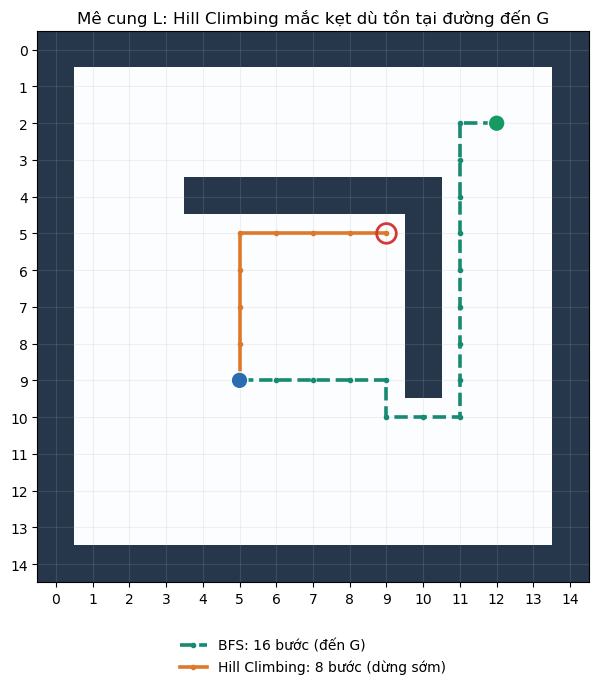

BFS tìm đường 16 bước đến G; Hill Climbing dừng tại (5, 9), h còn 6.


In [8]:
from collections import deque
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


def bfs_reference(maze):
    """Chỉ dùng để kiểm chứng tính tồn tại của đường S -> G."""
    start, goal = mh.find_pos(maze, 'S'), mh.find_pos(maze, 'G')
    queue = deque([start])
    parent = {start: None}
    directions = ((-1, 0), (0, 1), (1, 0), (0, -1))
    while queue:
        r, c = queue.popleft()
        if (r, c) == goal:
            path = []
            pos = goal
            while pos is not None:
                path.append(pos)
                pos = parent[pos]
            return path[::-1]
        for dr, dc in directions:
            nxt = (r + dr, c + dc)
            if (0 <= nxt[0] < maze.shape[0]
                and 0 <= nxt[1] < maze.shape[1]
                and maze[nxt] != 'X' and nxt not in parent):
                parent[nxt] = (r, c)
                queue.append(nxt)
    return None

bfs_path = bfs_reference(maze)
assert bfs_path is not None, 'Không có đường BFS trên dữ liệu hiện tại.'
assert all(maze[rc] != 'X' for rc in bfs_path)

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(maze == 'X', cmap=ListedColormap(['#fbfdff', '#26364b']),
          origin='upper', interpolation='nearest')
for positions, color, label, style in [
    (bfs_path, '#168a72', f'BFS: {len(bfs_path)-1} bước (đến G)', '--'),
    (result['trace'], '#dc792a', f'Hill Climbing: {result["steps"]} bước (dừng sớm)', '-')
]:
    rows, cols = zip(*positions)
    ax.plot(cols, rows, style, color=color, linewidth=2.6, marker='o',
            markersize=3, label=label)
ax.scatter([start_pos[1], goal_pos[1]], [start_pos[0], goal_pos[0]],
           c=['#2b6cb0', '#159b62'], s=145, zorder=5, edgecolors='white')
ax.text(start_pos[1], start_pos[0], 'S', color='white', ha='center', va='center', weight='bold')
ax.text(goal_pos[1], goal_pos[0], 'G', color='white', ha='center', va='center', weight='bold')
ax.scatter(result['solution'][1], result['solution'][0],
           facecolors='none', edgecolors='#d33939', linewidths=2, s=200, zorder=6)
ax.set_xticks(range(maze.shape[1])); ax.set_yticks(range(maze.shape[0]))
ax.grid(alpha=0.18)
ax.set_title('Mê cung L: Hill Climbing mắc kẹt dù tồn tại đường đến G')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.tight_layout()
plt.show()

print(f'BFS tìm đường {len(bfs_path)-1} bước đến G; '
      f'Hill Climbing dừng tại {result["solution"]}, h còn {result["h_history"][-1]}.')

## 5. Thí nghiệm: thay thứ tự hướng và lựa chọn ngẫu nhiên

**Thiết kế:** thay bốn thứ tự `NESW`, `WSEN`, `ESNW`, `SNEW`, sau đó chạy 100 seed (`0..99`) với `set_order('NESW', random=True)`. Đối với các lần có yếu tố ngẫu nhiên, gọi `np.random.seed(seed)` trước mỗi lần để tái lập kết quả. Giữ **nguyên** `maze`, `manhattan()`, `expand()` và quy tắc chọn láng giềng tốt nhất. So sánh vị trí dừng, giá trị `h`, số bước, số lần đánh giá và số đường đi khác nhau.

**Cần phân biệt:** đổi thứ tự có thể tạo ra đường đi khác khi hòa điểm, nhưng không tương đương cho phép bước xấu; vì vậy không nhất thiết giải quyết được cực trị cục bộ.

In [9]:
import pandas as pd

records = []
paths_by_run = {}
fixed_orders = ['NESW', 'WSEN', 'ESNW', 'SNEW']

for order in fixed_orders:
    set_order(order, random=False, verbose=False)
    r = local_search(maze)
    name = f'Fixed {order}'
    paths_by_run[name] = tuple(r['trace'])
    records.append({'cấu hình': name, 'đích': r['success'], 'dừng tại': str(r['solution']),
                    'h cuối': r['h_history'][-1], 'bước': r['steps'],
                    'lượt tính h': r['evaluations']})

random_results = []
set_order('NESW', random=True, verbose=False)
for seed in range(100):
    np.random.seed(seed)
    r = local_search(maze)
    random_results.append(r)
    paths_by_run[f'Seed {seed}'] = tuple(r['trace'])

set_order('NESW', random=False, verbose=False)  # khôi phục để thử nghiệm sau tái lập
fixed_df = pd.DataFrame(records)
random_unique_paths = len({tuple(r['trace']) for r in random_results})
random_successes = sum(r['success'] for r in random_results)
random_endpoints = {r['solution'] for r in random_results}
random_averages = {'bước TB': np.mean([r['steps'] for r in random_results]),
                   'lượt tính h TB': np.mean([r['evaluations'] for r in random_results])}

print('KẾT QUẢ THỨ TỰ HƯỚNG CỐ ĐỊNH')
display(fixed_df)
print(f'\n100 lượt RANDOMIZATION: thành công {random_successes}/100; '
      f'{random_unique_paths} đường đi phân biệt; {len(random_endpoints)} điểm dừng phân biệt.')
print('Các điểm dừng:', sorted(random_endpoints))
print('Trung bình:', {key: float(round(float(value), 2)) for key, value in random_averages.items()})

KẾT QUẢ THỨ TỰ HƯỚNG CỐ ĐỊNH


,cấu hình,đích,dừng tại,h cuối,bước,lượt tính h
0,Fixed NESW,False,"(5, 9)",6,8,31
1,Fixed WSEN,False,"(5, 9)",6,8,31
2,Fixed ESNW,False,"(5, 9)",6,8,31
3,Fixed SNEW,False,"(5, 9)",6,8,31



100 lượt RANDOMIZATION: thành công 0/100; 48 đường đi phân biệt; 1 điểm dừng phân biệt.
Các điểm dừng: [(5, 9)]
Trung bình: {'bước TB': 8.0, 'lượt tính h TB': 32.83}


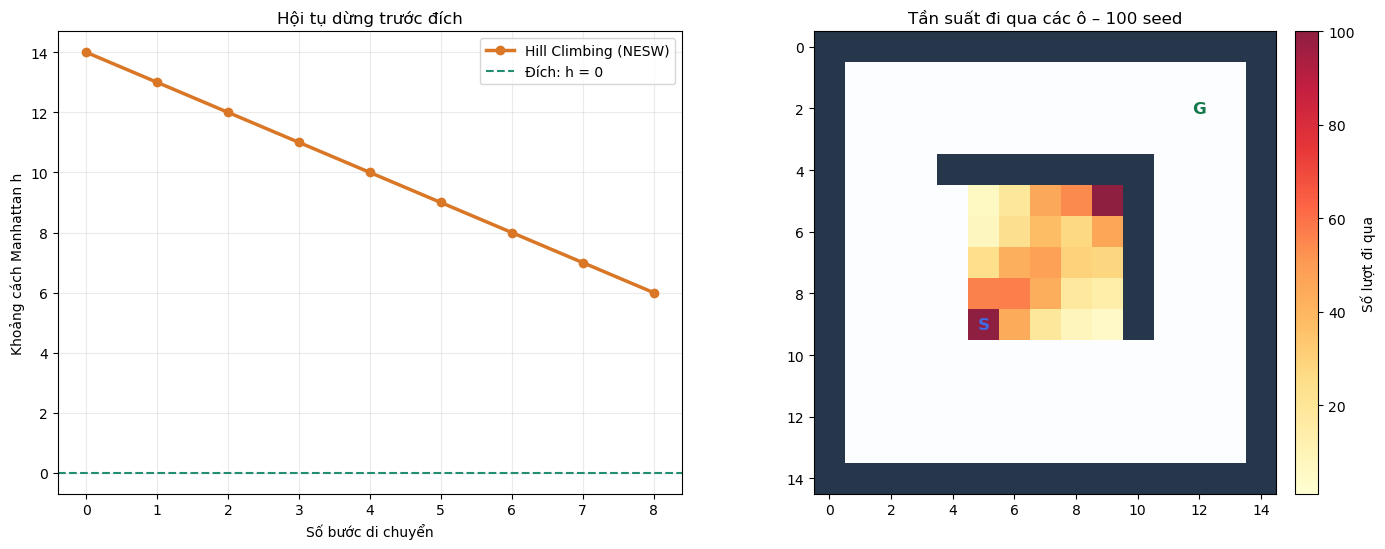

In [10]:
from matplotlib import colors

# (a) Hội tụ: h giảm dần nhưng không về 0.
# (b) Heatmap tần suất ô được đi qua trong 100 lượt ngẫu nhiên.
visits = np.zeros(maze.shape, dtype=int)
for r in random_results:
    for pos in r['trace']:
        visits[pos] += 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6))
ax1.plot(range(len(result['h_history'])), result['h_history'],
         '-o', color='#d97726', linewidth=2.5, label='Hill Climbing (NESW)')
ax1.axhline(0, linestyle='--', color='#228d71', label='Đích: h = 0')
ax1.set_xlabel('Số bước di chuyển'); ax1.set_ylabel('Khoảng cách Manhattan h')
ax1.set_title('Hội tụ dừng trước đích')
ax1.grid(alpha=0.25); ax1.legend()

ax2.imshow(maze == 'X', cmap=ListedColormap(['#fbfdff', '#26364b']), interpolation='nearest')
heat = ax2.imshow(np.ma.masked_where(visits == 0, visits), cmap='YlOrRd',
                  vmin=1, vmax=100, alpha=0.88, interpolation='nearest')
for marker, point in [('S', start_pos), ('G', goal_pos)]:
    ax2.text(point[1], point[0], marker, ha='center', va='center',
             color='royalblue' if marker == 'S' else '#14794c', weight='bold', fontsize=12)
ax2.set_title('Tần suất đi qua các ô – 100 seed')
ax2.set_xticks(range(0, maze.shape[1], 2)); ax2.set_yticks(range(0, maze.shape[0], 2))
fig.colorbar(heat, ax=ax2, fraction=0.045, pad=0.03, label='Số lượt đi qua')
plt.tight_layout()
plt.show()

## 6. Kiểm tra tính đúng và thảo luận

**Kiểm tra:** xác nhận các bước nằm trong ô hợp lệ, liên tiếp theo N/E/S/W, `h` giảm tại mỗi bước và điều kiện dừng đúng; thử thêm tình huống không có láng giềng để tránh lỗi `min([])`. Kiểm tra được áp dụng cho lần chạy mặc định, các cấu hình cố định và 100 lượt ngẫu nhiên.

**Giới hạn thực nghiệm:** Kết luận chỉ áp dụng cho `L_maze.txt`, heuristic Manhattan và cách chọn láng giềng của notebook. Kết quả thời gian rất nhỏ, phụ thuộc máy; không nên kết luận thuật toán nhanh/chậm chỉ từ một phép đo đơn lẻ.

In [11]:
all_results = [result] + [*random_results]
# Bổ sung kết quả từ các hướng cố định mà không dùng trạng thái random còn sót lại.
for order in fixed_orders:
    set_order(order, random=False, verbose=False)
    all_results.append(local_search(maze))
set_order('NESW', random=False, verbose=False)

for r in all_results:
    trace = r['trace']
    assert trace[0] == start_pos
    assert r['steps'] == len(trace) - 1
    assert r['h_history'] == [manhattan(p, goal_pos) for p in trace]
    assert all(maze[p] != 'X' for p in trace)
    assert all(abs(a[0]-b[0]) + abs(a[1]-b[1]) == 1
               for a, b in zip(trace, trace[1:]))
    assert all(h2 < h1 for h1, h2 in zip(r['h_history'], r['h_history'][1:]))
    assert r['success'] == (r['solution'] == goal_pos)
    if not r['success'] and r['stop_reason'] == 'no_improvement':
        assert all(manhattan(p, goal_pos) >= r['h_history'][-1]
                   for _, p in expand(maze, r['solution']))

# Test trường hợp đặc biệt: S bị vây kín, không có hàng xóm.
trapped = mh.parse_maze('XXXXX\nXSXGX\nXXXXX')
trapped_result = local_search(trapped)
assert trapped_result['stop_reason'] == 'no_neighbors'
assert trapped_result['steps'] == 0 and not trapped_result['success']

stop_neighbors = [(direction, tuple(map(int, pos)), manhattan(pos, goal_pos))
                  for direction, pos in expand(maze, result['solution'])]
print(f'PASS: đã kiểm tra {len(all_results)} lần chạy chính và trường hợp không có láng giềng.')
print('Các láng giềng tại điểm dừng (hướng, vị trí, h):', stop_neighbors)

PASS: đã kiểm tra 105 lần chạy chính và trường hợp không có láng giềng.
Các láng giềng tại điểm dừng (hướng, vị trí, h): [('S', (6, 9), 7), ('W', (5, 8), 7)]


In [12]:
from IPython.display import Markdown

stop = result['solution']
stop_h = result['h_history'][-1]
summary = (
    f"**Kết quả mặc định (`NESW`):** S={start_pos}, G={goal_pos}, thuật toán đi "
    f"**{result['steps']} bước**, từ h={result['h_history'][0]} xuống **h={stop_h}**, "
    f"dừng tại **{stop}**, không đạt G. "
    f"Tại vị trí này, các láng giềng hợp lệ có h="
    f"{[h for _, _, h in stop_neighbors]}, không có bước cải thiện.\n\n"
    f"**Đổi thứ tự:** {len(fixed_orders)} cấu hình được thử. "
    f"**Ngẫu nhiên hóa:** {len(random_results)} seed, tỷ lệ thành công "
    f"**{100*random_successes/len(random_results):.1f}%**, "
    f"có **{random_unique_paths}** đường đi phân biệt và "
    f"**{len(random_endpoints)}** vị trí dừng phân biệt. "
    f"**BFS đối chứng:** tồn tại đường đến G dài **{len(bfs_path)-1} bước**. "
    f"Đây là bằng chứng thuật toán mắc kẹt do quy tắc cải thiện cục bộ, "
    f"không phải vì bản đồ không có nghiệm."
)
display(Markdown(summary))

**Kết quả mặc định (`NESW`):** S=(9, 5), G=(2, 12), thuật toán đi **8 bước**, từ h=14 xuống **h=6**, dừng tại **(5, 9)**, không đạt G. Tại vị trí này, các láng giềng hợp lệ có h=[7, 7], không có bước cải thiện.

**Đổi thứ tự:** 4 cấu hình được thử. **Ngẫu nhiên hóa:** 100 seed, tỷ lệ thành công **0.0%**, có **48** đường đi phân biệt và **1** vị trí dừng phân biệt. **BFS đối chứng:** tồn tại đường đến G dài **16 bước**. Đây là bằng chứng thuật toán mắc kẹt do quy tắc cải thiện cục bộ, không phải vì bản đồ không có nghiệm.

### Kết luận Bài 1

- Khoảng cách Manhattan cung cấp tín hiệu cải thiện cục bộ, nhưng **không mô tả được vật cản và đường vòng**.
- Một thuật toán chỉ chấp nhận `h` giảm nghiêm ngặt có thể dừng trước `G`, kể cả khi tồn tại đường đi hợp lệ.
- Thay đổi thứ tự hướng hoặc xáo trộn láng giềng chỉ thay cách phá hòa; không khắc phục được bẫy phải **đi xa đích tạm thời**.
- Những cải tiến như cho phép đi ngang, Random Restart hoặc Simulated Annealing thuộc phần tìm kiếm cục bộ tiếp theo và không được lẫn với kết quả **Hill Climbing gốc** ở Bài 1.

**Tự đánh giá:** Đã thực hiện các mục trong PDF: hiển thị mê cung, phân tích N/E/S/W và `expand`, tính Manhattan, chạy `local_search` có animation, ghi nhận `result["solution"]`, giải thích dừng sớm, thử đổi `ORDER` và `RANDOMIZATION`, kiểm tra tính đúng. Notebook có thể chạy từ đầu khi mở tại thư mục Lab03 hoặc gốc repository và không phụ thuộc tải dữ liệu ngoài.